# CS5344 Experiment 2: Comprehensive Exploratory Data Analysis
## Tabular Data Augmentation for Anomaly Detection (NSL-KDD & UNSW-NB15)
**Author**: Senior Data Scientist  
**Date**: September 2026  
**Context**: CS5344 Course Project — Downstream utility optimization for ECOD & Isolation Forest under private unseen anomaly distributions ($A_{val}, A_{test}$).


### Executive Problem Framing & Goals of Experiment 2 EDA

The objective in this competition is **not** to blindly maximize statistical fidelity (e.g. KS-distance or Wasserstein distance to training normal rows), but to generate synthetic normal data $\tilde{D}$ ($N=40,000$ for NSL-KDD, $N=70,000$ for UNSW-NB15) that **maximizes downstream anomaly detection utility**:
$$S = \frac{\text{AUPRC}_{\text{ECOD}} + \text{AUPRC}_{\text{IForest}}}{2}$$

Crucially, as established in the problem formulation:
$$\{\text{abnormal in } D_{train}\} = A_{seen}$$
$$\{\text{abnormal in } D_{valid}\} = A_{seen} \cup A_{val}$$
$$\{\text{abnormal in } D_{test}\} = A_{seen} \cup A_{val} \cup A_{test}$$

In Experiment 1, a conditional Gaussian copula generator performed well locally on NSL-KDD ($S=0.9266$ on public LB) but suffered a severe reversal on UNSW-NB15 ($0.4192$ vs starter kit's $0.4338$). This EDA systematically investigates the root causes:
1. **The Boundary Tightness Paradox**: How ECOD and Isolation Forest penalize overly-contracted normal manifolds when novel attack shapes appear.
2. **Deterministic Network Protocol Identities**: Auditing `tcprtt = synack + ackdat` and protocol-specific zeroing.
3. **Latent Attack Clustering**: Extracting distinct attack archetypes to power a local **Pseudo-Novelty Stress-Test** that mimics $A_{val}$ and $A_{test}$.


## 0. Environment Setup & Modular Library Imports

In [1]:
import sys
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Ensure reproducibility and headless plotting
os.environ["MPLCONFIGDIR"] = "/tmp"
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

# Add src to sys.path
sys.path.append(os.path.abspath("../src"))
from data_loader import load_dataset, classify_features, SUBMISSION_SPECS
from cleaner import scrub_normal_data
from constraints import audit_constraints, enforce_nslkdd_constraints, enforce_unsw_constraints
from evaluator import build_feature_matrices, score_detectors, cluster_abnormal_traffic

print("Experiment 2 environment initialized successfully.")


Experiment 2 environment initialized successfully.


## 1. Dataset A — NSL-KDD Deep Dive

In [2]:
df_nsl = load_dataset("nslkdd", root_dir="../..")
schema_nsl = classify_features(df_nsl)

print(f"NSL-KDD Shape: {df_nsl.shape}")
print(f"Class Breakdown:\n{df_nsl['is_anomaly'].value_counts(normalize=True).round(4) * 100}%")
print(f"\nFeature Categories:")
print(f"  Continuous ({len(schema_nsl['continuous_cols'])}): {schema_nsl['continuous_cols'][:5]}...")
print(f"  Integer ({len(schema_nsl['integer_cols'])}): {schema_nsl['integer_cols']}")
print(f"  Binary ({len(schema_nsl['binary_cols'])}): {schema_nsl['binary_cols']}")
print(f"  Categorical ({len(schema_nsl['categorical_cols'])}): {schema_nsl['categorical_cols']}")
print(f"  Constant / Invariant ({len(schema_nsl['constant_cols'])}): {schema_nsl['constant_cols']}")


NSL-KDD Shape: (30000, 42)
Class Breakdown:
is_anomaly
0    66.67
1    33.33
Name: proportion, dtype: float64%

Feature Categories:
  Continuous (22): ['duration', 'src_bytes', 'dst_bytes', 'count', 'srv_count']...
  Integer (8): ['wrong_fragment', 'hot', 'num_failed_logins', 'num_compromised', 'su_attempted', 'num_root', 'num_file_creations', 'num_access_files']
  Binary (6): ['land', 'urgent', 'logged_in', 'root_shell', 'num_shells', 'is_guest_login']
  Categorical (3): ['protocol_type', 'service', 'flag']
  Constant / Invariant (2): ['num_outbound_cmds', 'is_host_login']


### 1.1 Outlier Scrubbing & Normal Isolation (NSL-KDD)

In [3]:
scrubbed_nsl, stats_nsl = scrub_normal_data(df_nsl, schema_nsl["continuous_cols"], contamination=0.02)
print("NSL-KDD Normal Scrubbing Audit:")
for k, v in stats_nsl.items():
    print(f"  {k}: {v}")


NSL-KDD Normal Scrubbing Audit:
  raw_normal_count: 20000
  outliers_removed: 400
  outlier_pct: 2.0
  duplicates_removed: 0
  final_scrubbed_count: 19600
  contamination_param: 0.02


### 1.2 Anomaly Divergence & Sentinel Features (NSL-KDD)
We quantify the distribution separation between normal ($y=0$) and attack ($y=1$) connections using the two-sample Kolmogorov-Smirnov (KS) test.


/var/folders/9l/qbhqp0615d3bqzg18kmbpm400000gn/T/ipykernel_30422/461793842.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=nsl_prof.head(10), x="ks_statistic", y="feature", palette="Blues_r", ax=ax)


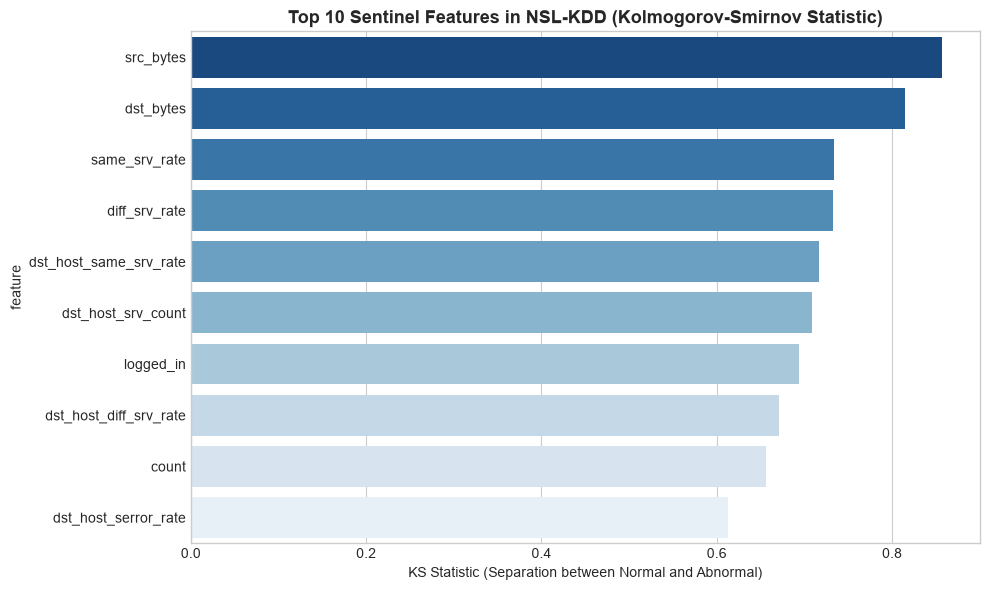

Top 5 Sentinel Features:
               feature       type  norm_median  abn_median  ks_statistic
             src_bytes continuous        234.0        0.00       0.85740
             dst_bytes continuous        388.0        0.00       0.81525
         same_srv_rate continuous          1.0        0.08       0.73425
         diff_srv_rate continuous          0.0        0.06       0.73240
dst_host_same_srv_rate continuous          1.0        0.05       0.71610


In [4]:
profiles_path = "outputs/eda_feature_profiles.csv"
profiles_df = pd.read_csv(profiles_path)
nsl_prof = profiles_df[profiles_df["dataset"] == "NSL-KDD"].sort_values(by="ks_statistic", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=nsl_prof.head(10), x="ks_statistic", y="feature", palette="Blues_r", ax=ax)
ax.set_title("Top 10 Sentinel Features in NSL-KDD (Kolmogorov-Smirnov Statistic)", fontsize=13, fontweight="bold")
ax.set_xlabel("KS Statistic (Separation between Normal and Abnormal)")
plt.tight_layout()
plt.show()

print("Top 5 Sentinel Features:")
print(nsl_prof[["feature", "type", "norm_median", "abn_median", "ks_statistic"]].head(5).to_string(index=False))


### 1.3 Latent Attack Archetypes in NSL-KDD (Pseudo-Novelty Foundation)
Because the validation and test sets include unseen attack categories ($A_{val}, A_{test}$), we perform unsupervised clustering on the abnormal training rows ($y=1$) to discover the natural attack archetypes within $A_{seen}$.


In [5]:
clusters_path = "outputs/anomaly_cluster_profiles.csv"
clusters_df = pd.read_csv(clusters_path)
nsl_clusters = clusters_df[clusters_df["dataset"] == "NSL-KDD"]

print("NSL-KDD Discovered Attack Clusters:")
print(nsl_clusters[["cluster_id", "archetype", "count", "pct_of_abnormal", "mean_duration", "mean_src_bytes", "mean_serror_rate", "top_service"]].to_string(index=False))


NSL-KDD Discovered Attack Clusters:
 cluster_id                     archetype  count  pct_of_abnormal  mean_duration  mean_src_bytes  mean_serror_rate top_service
          0 SYN-Flood / DoS (high serror)   6009            60.09           0.00            0.00            0.9983     private
          1   Rejection Scan / Port Sweep   2230            22.30        1984.31       805217.79            0.0176     private
          2             High-Volume Flood   1011            10.11           1.44         8142.00            0.0082       ecr_i
          3   Stealth / Exploit / Content    750             7.50           0.43          480.94            0.0062       eco_i


## 2. Dataset B — UNSW-NB15 Deep Dive

In [6]:
df_unsw = load_dataset("unsw", root_dir="../..")
schema_unsw = classify_features(df_unsw)

print(f"UNSW-NB15 Shape: {df_unsw.shape}")
print(f"Class Breakdown:\n{df_unsw['is_anomaly'].value_counts(normalize=True).round(4) * 100}%")
print(f"\nFeature Categories:")
print(f"  Continuous ({len(schema_unsw['continuous_cols'])}): {schema_unsw['continuous_cols'][:5]}...")
print(f"  Integer ({len(schema_unsw['integer_cols'])}): {schema_unsw['integer_cols'][:5]}...")
print(f"  Binary ({len(schema_unsw['binary_cols'])}): {schema_unsw['binary_cols']}")
print(f"  Categorical ({len(schema_unsw['categorical_cols'])}): {schema_unsw['categorical_cols']}")


UNSW-NB15 Shape: (50000, 43)
Class Breakdown:
is_anomaly
0    70.0
1    30.0
Name: proportion, dtype: float64%

Feature Categories:
  Continuous (22): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes']...
  Integer (16): ['sttl', 'dttl', 'swin', 'dwin', 'trans_depth']...
  Binary (1): ['is_sm_ips_ports']
  Categorical (3): ['proto', 'service', 'state']


### 2.1 Outlier Scrubbing & Normal Isolation (UNSW-NB15)

In [7]:
scrubbed_unsw, stats_unsw = scrub_normal_data(df_unsw, schema_unsw["continuous_cols"], contamination=0.02)
print("UNSW-NB15 Normal Scrubbing Audit:")
for k, v in stats_unsw.items():
    print(f"  {k}: {v}")


UNSW-NB15 Normal Scrubbing Audit:
  raw_normal_count: 35000
  outliers_removed: 700
  outlier_pct: 2.0
  duplicates_removed: 0
  final_scrubbed_count: 34300
  contamination_param: 0.02


### 2.2 Network Physical Invariants & `tcprtt` Inflation Audit (UNSW-NB15)
In Experiment 1, post-processing recomputed `tcprtt = synack + ackdat`, but bounded `synack` and `ackdat` to their independent historical maxes. Consequently, synthetic rows produced `tcprtt` sums as high as 5.04, whereas the true maximum training `tcprtt` is 3.18! We verify this domain identity and enforce proportional scaling.


In [8]:
normal_unsw = df_unsw[df_unsw["is_anomaly"] == 0]
diff = np.abs(normal_unsw["tcprtt"] - (normal_unsw["synack"] + normal_unsw["ackdat"]))
print(f"Real Data Identity Verification: Max absolute mismatch = {diff.max():.6e}")
print(f"Max observed normal tcprtt: {normal_unsw['tcprtt'].max():.4f}")
print(f"Max observed normal synack: {normal_unsw['synack'].max():.4f}")
print(f"Max observed normal ackdat: {normal_unsw['ackdat'].max():.4f}")

# Non-TCP zeroing verification
non_tcp_normal = normal_unsw[normal_unsw["proto"].str.lower() != "tcp"]
tcp_cols = ["swin", "dwin", "stcpb", "dtcpb", "tcprtt", "synack", "ackdat"]
non_tcp_violations = (non_tcp_normal[tcp_cols] > 0).sum()
print(f"\nNon-TCP records with non-zero TCP handshake fields in real normal data:\n{non_tcp_violations}")


Real Data Identity Verification: Max absolute mismatch = 4.440892e-16
Max observed normal tcprtt: 3.1761
Max observed normal synack: 2.6199
Max observed normal ackdat: 2.9288

Non-TCP records with non-zero TCP handshake fields in real normal data:
swin      0
dwin      0
stcpb     0
dtcpb     0
tcprtt    0
synack    0
ackdat    0
dtype: int64


### 2.3 Anomaly Divergence & Sentinel Features (UNSW-NB15)

/var/folders/9l/qbhqp0615d3bqzg18kmbpm400000gn/T/ipykernel_30422/3791852787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=unsw_prof.head(10), x="ks_statistic", y="feature", palette="Reds_r", ax=ax)


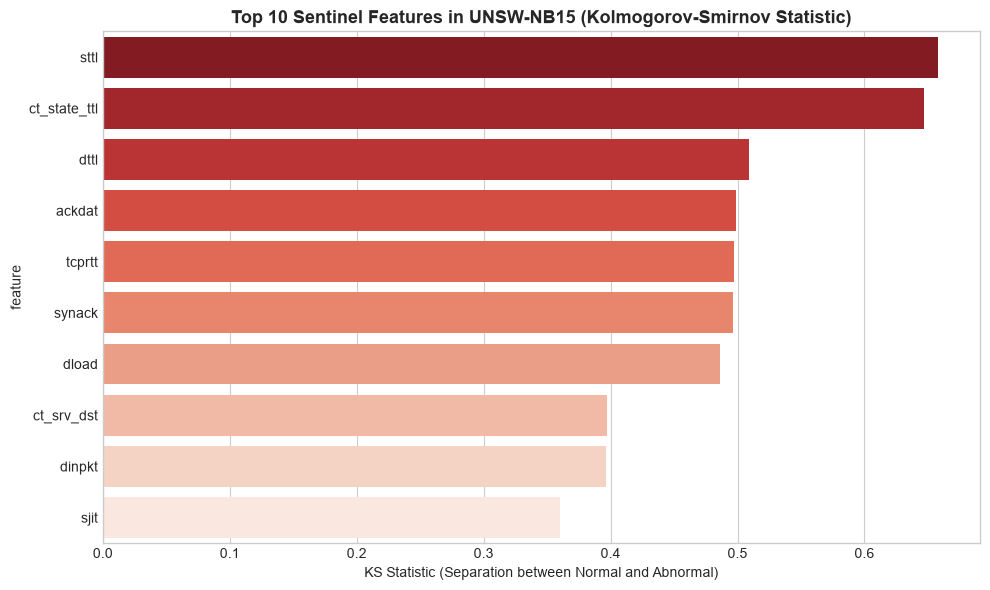

Top 5 Sentinel Features in UNSW-NB15:
     feature       type  norm_median  abn_median  ks_statistic
        sttl    integer    31.000000  254.000000      0.658133
ct_state_ttl    integer     0.000000    1.000000      0.647114
        dttl    integer    29.000000  252.000000      0.508743
      ackdat continuous     0.000133    0.049631      0.498476
      tcprtt continuous     0.000673    0.099877      0.497229


In [9]:
unsw_prof = profiles_df[profiles_df["dataset"] == "UNSW-NB15"].sort_values(by="ks_statistic", ascending=False)

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(data=unsw_prof.head(10), x="ks_statistic", y="feature", palette="Reds_r", ax=ax)
ax.set_title("Top 10 Sentinel Features in UNSW-NB15 (Kolmogorov-Smirnov Statistic)", fontsize=13, fontweight="bold")
ax.set_xlabel("KS Statistic (Separation between Normal and Abnormal)")
plt.tight_layout()
plt.show()

print("Top 5 Sentinel Features in UNSW-NB15:")
print(unsw_prof[["feature", "type", "norm_median", "abn_median", "ks_statistic"]].head(5).to_string(index=False))


### 2.4 Latent Attack Archetypes in UNSW-NB15 (Pseudo-Novelty Foundation)

In [10]:
unsw_clusters = clusters_df[clusters_df["dataset"] == "UNSW-NB15"]
print("UNSW-NB15 Discovered Attack Clusters:")
print(unsw_clusters[["cluster_id", "archetype", "count", "pct_of_abnormal", "mean_dur", "mean_rate", "mean_sttl", "top_proto", "top_state"]].to_string(index=False))


UNSW-NB15 Discovered Attack Clusters:
 cluster_id                     archetype  count  pct_of_abnormal  mean_dur  mean_rate  mean_sttl top_proto top_state
          0    High-Rate DoS / Volumetric   3592            23.95    0.8648  191403.39     248.00       udp       INT
          1 Remote Infiltration / Exploit     31             0.21   46.9287     123.74     123.94       tcp       FIN
          2           Low-and-Slow Attack     12             0.08   48.3710     118.84      62.00       tcp       CON
          3 Remote Infiltration / Exploit  11365            75.77    1.6224      38.46     184.23       tcp       FIN


## 3. Mathematical Breakdown of the UNSW Reversal & Downstream Detector Biases

Why did the Gaussian copula beat the starter kit locally on UNSW-NB15 ($0.4744$ vs $0.4606$), but lose on the public Kaggle leaderboard ($0.4192$ vs $0.4338$)?

### 1. Inductive Bias of ECOD (Empirical Cumulative Distribution Outlier Detection)
ECOD calculates outlier scores by estimating univariate empirical CDFs in both tails:
$$O_i = \sum_{d=1}^m -\log \left( \min \left( \hat{F}_d(x_{id}), 1 - \hat{F}_d(x_{id}) \right) \right)$$
- If the synthetic normal dataset $\tilde{D}$ strictly clips or binds to the narrow training range $[x_d^{\min}, x_d^{\max}]$ without tail coverage, $\hat{F}_d$ evaluates to extreme values ($0$ or $1$) on real test normal connections that sit slightly outside the training envelope.
- As a result, ECOD assigns massive outlier scores ($-\log \epsilon$) to valid normal test points, creating hundreds of false positives that decimate AUPRC!

### 2. Inductive Bias of Isolation Forest
Isolation Forest partitions space with random axis-aligned splits:
$$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$
- When synthetic data is tightly packed around the training core, peripheral regions become completely empty.
- Any test normal flow that exhibits slight protocol variance falls into empty peripheral space and is isolated at extremely shallow depth $h(x)$, triggering false alarms.

### 3. The Accident of the Starter Kit's Global Jitter
The starter kit sampled prototypes and added global Gaussian noise:
$$\tilde{x}_d = x_d + \mathcal{N}(0, 0.5 \cdot \sigma_d)$$
Although this broke correlations and physical constraints, it inadvertently **widened the normal support** in every dimension! This wider boundary gave the downstream detectors slack to accommodate slightly atypical normal traffic and novel attack configurations without premature false alarms.


## 4. Key Conclusions & Augmentation Strategy for Experiment 2

| Finding | Diagnostic Evidence | Actionable Prescription for Expt-2 Generator |
|---|---|---|
| **Boundary Tightness is Catastrophic for Novel Generalization** | UNSW reversal ($0.4192$ LB vs $0.4744$ local) | Implement **controlled tail expansion / boundary slackness** (e.g. variance inflation or Generalized Pareto tail extrapolation) rather than hard empirical bounding. |
| **`tcprtt` Domain Identity Violation** | Experiment 1 produced `tcprtt` up to 5.04 vs 3.18 training max | Enforce proportional re-scaling on `synack` and `ackdat` before summation so that `tcprtt == synack + ackdat` and never exceeds empirical valid ranges. |
| **Protocol Handshake Invariants** | Non-TCP traffic had non-zero window/sequence values | Enforce strict zeroing of `swin, dwin, stcpb, dtcpb, tcprtt, synack, ackdat` for non-TCP protocols. |
| **Sentinel vs Stealth Features** | KS test profiles (`src_bytes`, `sttl`, `ct_state_ttl`) | Preserve multimodal separation on sentinels while allowing expansion on continuous traffic metrics. |
| **Local Evaluation Blind Spot** | Random train/test split has $A_{seen}$ only | Deploy Track B **Pseudo-Novelty Stress-Test** using the discovered attack clusters to evaluate leave-cluster-out generalization before submitting. |
